# The "Last Mile" Logistics Auditor

This notebook checks Veridi Logistics' delivery data to find out why customer reviews are getting worse.
We go step by step: explore the data, join the tables, measure delays, compare states, and link delays to reviews.

## Step 0: Setup

We import the libraries we need.
The data files must be in a data/olist folder next to this notebook.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 50)
plt.rcParams["figure.figsize"] = (10, 5)

/home/emmilina/.local/lib/python3.12/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


## Step 1: Load the data

The CSV files are in the data/olist folder next to this notebook.
We use a relative path so the code works on any computer.

In [2]:
DATA_DIR = "data/olist/"

orders = pd.read_csv(DATA_DIR + "olist_orders_dataset.csv")
reviews = pd.read_csv(DATA_DIR + "olist_order_reviews_dataset.csv")
customers = pd.read_csv(DATA_DIR + "olist_customers_dataset.csv")
products = pd.read_csv(DATA_DIR + "olist_products_dataset.csv")
items = pd.read_csv(DATA_DIR + "olist_order_items_dataset.csv")
translation = pd.read_csv(DATA_DIR + "product_category_name_translation.csv")

## Step 2: Explore the data

Before joining anything, we look at each table.
This helps us spot missing values and duplicates early.

### 2.1 Size of each table

In [3]:
tables = {
    "orders": orders,
    "reviews": reviews,
    "customers": customers,
    "products": products,
    "items": items,
    "translation": translation,
}

for name, df in tables.items():
    print(f"{name:12} {df.shape[0]:>7} rows   {df.shape[1]:>2} columns")

orders         99441 rows    8 columns
reviews        99224 rows    7 columns
customers      99441 rows    5 columns
products       32951 rows    9 columns
items         112650 rows    7 columns
translation       71 rows    2 columns


### 2.2 First look at the main tables

Orders is the central table and has all the dates.
Reviews has the score, and customers has the state.

In [4]:
orders.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [5]:
reviews.head()

,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18 00:00:00,2018-01-18 21:46:59
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10 00:00:00,2018-03-11 03:05:13
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,NaN,NaN,2018-02-17 00:00:00,2018-02-18 14:36:24
3,e64fb393e7b32834bb789ff8bb30750e,658677c97b385a9be170737859d3511b,5,NaN,Recebi bem antes do prazo estipulado.,2017-04-21 00:00:00,2017-04-21 22:02:06
4,f7c4243c7fe1938f181bec41a392bdeb,8e6bfb81e283fa7e4f11123a3fb894f1,5,NaN,Parabéns lojas lannister adorei comprar pela I...,2018-03-01 00:00:00,2018-03-02 10:26:53


In [6]:
customers.head()

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


### 2.3 Missing values

Missing delivery dates usually mean the order never reached the customer.
Many review comments are empty, but that is fine because we only need the score.

In [7]:
orders.isnull().sum()

order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

In [8]:
reviews.isnull().sum()

review_id                      0
order_id                       0
review_score                   0
review_comment_title       87656
review_comment_message     58247
review_creation_date           0
review_answer_timestamp        0
dtype: int64

### 2.4 Order status

Most orders are "delivered", but some were canceled or never shipped.
We will need to handle those separately.

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64


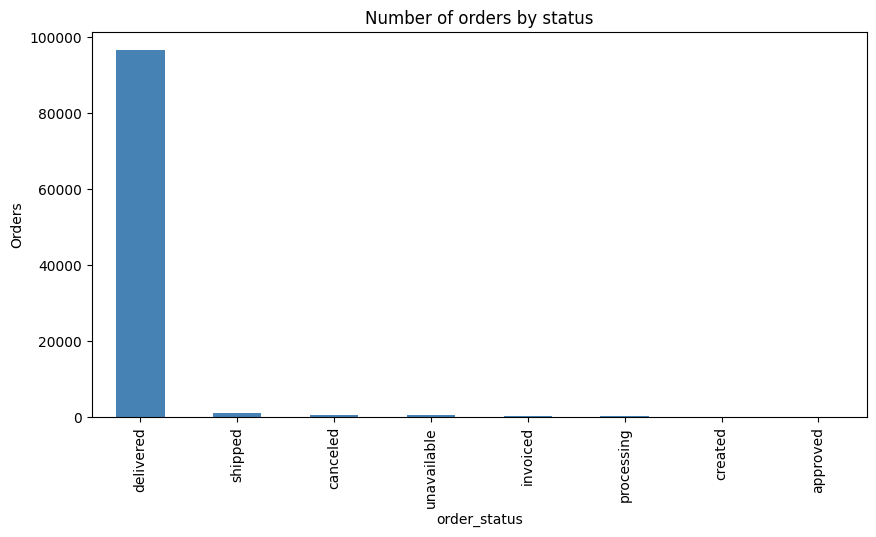

In [9]:
status_counts = orders["order_status"].value_counts()
print(status_counts)

status_counts.plot(kind="bar", color="steelblue")
plt.title("Number of orders by status")
plt.ylabel("Orders")
plt.show()

### 2.5 Review scores

Scores go from 1 (very bad) to 5 (very good).
This shows how happy customers are overall.

review_score
1    11424
2     3151
3     8179
4    19142
5    57328
Name: count, dtype: int64


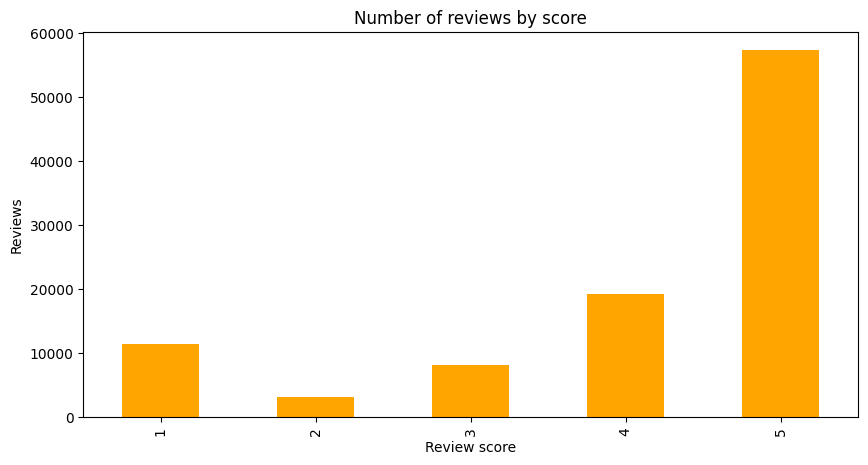

In [10]:
score_counts = reviews["review_score"].value_counts().sort_index()
print(score_counts)

score_counts.plot(kind="bar", color="orange")
plt.title("Number of reviews by score")
plt.xlabel("Review score")
plt.ylabel("Reviews")
plt.show()

### 2.6 Duplicate checks

Each order should appear once in the orders table, and each customer_id once in customers.
If reviews have more than one row per order, a join would copy those orders, so we check that too.

In [11]:
print("Orders: rows =", len(orders), "| unique order_id =", orders["order_id"].nunique())
print("Customers: rows =", len(customers), "| unique customer_id =", customers["customer_id"].nunique())
print("Reviews: rows =", len(reviews), "| unique order_id =", reviews["order_id"].nunique())

extra = len(reviews) - reviews["order_id"].nunique()
print("Orders with more than one review add", extra, "extra rows")

Orders: rows = 99441 | unique order_id = 99441
Customers: rows = 99441 | unique customer_id = 99441
Reviews: rows = 99224 | unique order_id = 98673
Orders with more than one review add 551 extra rows


### 2.7 Dates

We turn the date columns from text into real dates.
Then we check what time period the data covers.

First order: 2016-09-04 21:15:19
Last order:  2018-10-17 17:30:18


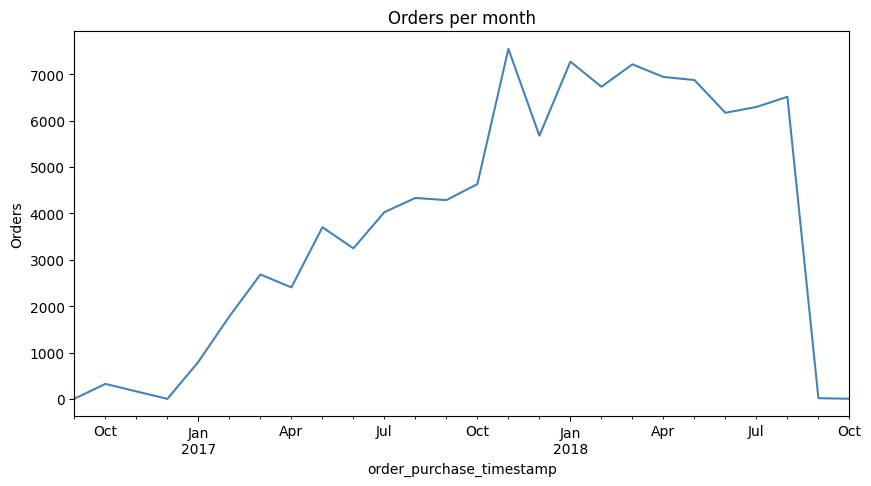

In [12]:
date_cols = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date",
]
for col in date_cols:
    orders[col] = pd.to_datetime(orders[col])

print("First order:", orders["order_purchase_timestamp"].min())
print("Last order: ", orders["order_purchase_timestamp"].max())

orders_per_month = orders["order_purchase_timestamp"].dt.to_period("M").value_counts().sort_index()
orders_per_month.plot(color="steelblue")
plt.title("Orders per month")
plt.ylabel("Orders")
plt.show()

## Step 3: Story 1 - Build the master dataset

We join orders, customers and reviews into one table, with one row per order.
First we fix the duplicate reviews so the join does not copy any orders.

### 3.1 Keep one review per order

If an order has more than one review, we keep the most recent one.
That is the customer's final opinion.

In [13]:
reviews["review_answer_timestamp"] = pd.to_datetime(reviews["review_answer_timestamp"])

reviews_clean = reviews.sort_values("review_answer_timestamp")
reviews_clean = reviews_clean.drop_duplicates(subset="order_id", keep="last")

print("Reviews before:", len(reviews))
print("Reviews after: ", len(reviews_clean))

Reviews before: 99224
Reviews after:  98673


### 3.2 Join the tables

We use a left join so that we keep every order, even ones without a review.
Customers join on customer_id and reviews join on order_id.

In [14]:
master = orders.merge(customers, on="customer_id", how="left")
master = master.merge(
    reviews_clean[["order_id", "review_score"]],
    on="order_id",
    how="left",
)

master.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state,review_score
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,7c396fd4830fd04220f754e42b4e5bff,3149,sao paulo,SP,4.0
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,af07308b275d755c9edb36a90c618231,47813,barreiras,BA,4.0
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,3a653a41f6f9fc3d2a113cf8398680e8,75265,vianopolis,GO,5.0
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,7c142cf63193a1473d2e66489a9ae977,59296,sao goncalo do amarante,RN,5.0
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,72632f0f9dd73dfee390c9b22eb56dd6,9195,santo andre,SP,5.0


### 3.3 Check for duplicate rows

The master table should have exactly the same number of rows as the orders table.
If not, the join made copies.

In [15]:
print("Rows in orders:", len(orders))
print("Rows in master:", len(master))
print("Each order appears once:", master["order_id"].is_unique)
print("Orders with no review:", master["review_score"].isnull().sum())

assert len(master) == len(orders), "The join created duplicate rows!"

Rows in orders: 99441
Rows in master: 99441
Each order appears once: True
Orders with no review: 768


## Step 4: Story 2 - The "real" delay

Now we compare the date we promised with the date the package really arrived.
Then we label each order On Time, Late, or Super Late.

### 4.1 Flag orders that were never delivered

An order counts as delivered only if its status is "delivered" and it has a delivery date.
The rest (canceled, unavailable, etc.) are flagged and left out of the delay analysis.

In [16]:
master["is_delivered"] = (master["order_status"] == "delivered") & (
    master["order_delivered_customer_date"].notnull()
)

print(master["is_delivered"].value_counts())
print()
print("Not delivered, by status:")
print(master.loc[~master["is_delivered"], "order_status"].value_counts())

is_delivered
True     96470
False     2971
Name: count, dtype: int64

Not delivered, by status:
order_status
shipped        1107
canceled        625
unavailable     609
invoiced        314
processing      301
delivered         8
created           5
approved          2
Name: count, dtype: int64


### 4.2 Calculate Days_Difference

Days_Difference = estimated delivery date minus actual delivery date.
A positive number means the order came early, and a negative number means it was late.

In [17]:
estimated = master["order_estimated_delivery_date"].dt.normalize()
delivered_on = master["order_delivered_customer_date"].dt.normalize()

master["Days_Difference"] = (estimated - delivered_on).dt.days

master.loc[~master["is_delivered"], "Days_Difference"] = np.nan

master[["order_id", "order_estimated_delivery_date", "order_delivered_customer_date", "Days_Difference"]].head()

,order_id,order_estimated_delivery_date,order_delivered_customer_date,Days_Difference
0,e481f51cbdc54678b7cc49136f2d6af7,2017-10-18,2017-10-10 21:25:13,8.0
1,53cdb2fc8bc7dce0b6741e2150273451,2018-08-13,2018-08-07 15:27:45,6.0
2,47770eb9100c2d0c44946d9cf07ec65d,2018-09-04,2018-08-17 18:06:29,18.0
3,949d5b44dbf5de918fe9c16f97b45f8a,2017-12-15,2017-12-02 00:28:42,13.0
4,ad21c59c0840e6cb83a9ceb5573f8159,2018-02-26,2018-02-16 18:17:02,10.0


### 4.3 Label each order

On Time = arrived on or before the promised date, Late = 1 to 5 days late, Super Late = more than 5 days late.
Orders that never arrived get the label "Not Delivered".

In [18]:
def get_status(days):
    if pd.isnull(days):
        return "Not Delivered"
    elif days >= 0:
        return "On Time"
    elif days >= -5:
        return "Late"
    else:
        return "Super Late"

master["Delivery_Status"] = master["Days_Difference"].apply(get_status)
master["is_late"] = master["Delivery_Status"].isin(["Late", "Super Late"])

print(master["Delivery_Status"].value_counts())

Delivery_Status
On Time          89936
Super Late        3764
Not Delivered     2971
Late              2770
Name: count, dtype: int64


From now on we only use delivered orders.
We also show the share of each status as a percent.

Delivery_Status
On Time       93.2
Late           2.9
Super Late     3.9
Name: proportion, dtype: float64


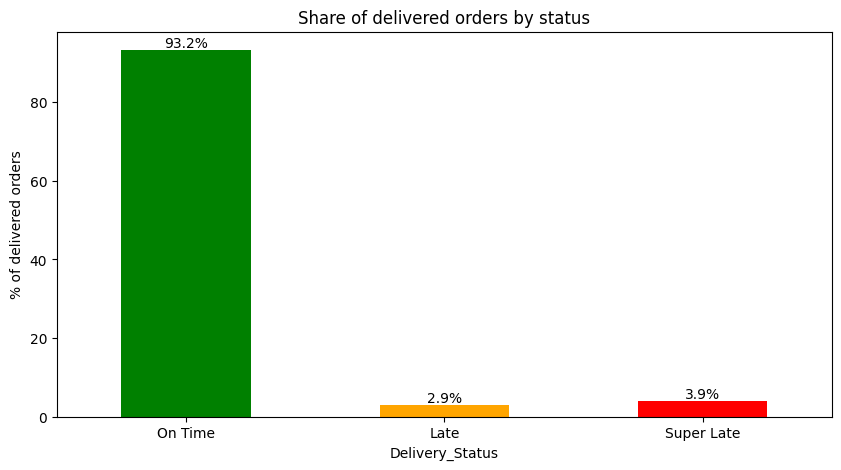

In [19]:
delivered = master[master["is_delivered"]].copy()

status_order = ["On Time", "Late", "Super Late"]
status_pct = delivered["Delivery_Status"].value_counts(normalize=True).reindex(status_order) * 100
print(status_pct.round(1))

ax = status_pct.plot(kind="bar", color=["green", "orange", "red"])
ax.bar_label(ax.containers[0], fmt="%.1f%%")
plt.title("Share of delivered orders by status")
plt.ylabel("% of delivered orders")
plt.xticks(rotation=0)
plt.show()

### 4.4 How good are our delivery estimates?

This chart shows how many days early or late orders arrived.
If most bars sit far to the right of zero, our estimates are too long, not too short.

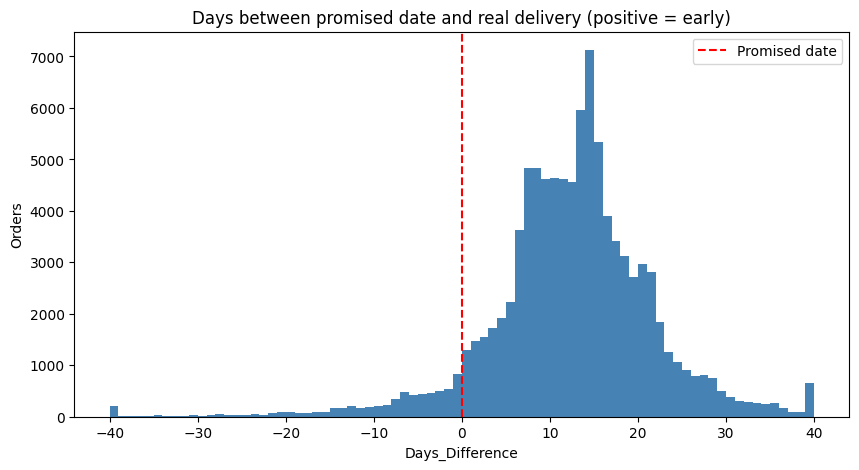

Average days we promised:   23.4
Average days it really took: 12.1
Median Days_Difference:      12.0


In [20]:
days = delivered["Days_Difference"].clip(-40, 40)

plt.hist(days, bins=80, color="steelblue")
plt.axvline(0, color="red", linestyle="--", label="Promised date")
plt.title("Days between promised date and real delivery (positive = early)")
plt.xlabel("Days_Difference")
plt.ylabel("Orders")
plt.legend()
plt.show()

promised_days = (delivered["order_estimated_delivery_date"] - delivered["order_purchase_timestamp"]).dt.days
actual_days = (delivered["order_delivered_customer_date"] - delivered["order_purchase_timestamp"]).dt.days

print("Average days we promised:  ", round(promised_days.mean(), 1))
print("Average days it really took:", round(actual_days.mean(), 1))
print("Median Days_Difference:     ", delivered["Days_Difference"].median())

## Step 5: Story 3 - Which states have the most late deliveries?

We work out the percent of late orders (Late + Super Late) in each state.
Then we check if remote states are hit harder.

### 5.1 Late percent per state

In [21]:
state_summary = delivered.groupby("customer_state").agg(
    orders=("order_id", "count"),
    late_orders=("is_late", "sum"),
    avg_days_difference=("Days_Difference", "mean"),
    avg_review=("review_score", "mean"),
)
state_summary["late_pct"] = state_summary["late_orders"] / state_summary["orders"] * 100
state_summary = state_summary.sort_values("late_pct", ascending=False)

state_summary.round(2)

,orders,late_orders,avg_days_difference,avg_review,late_pct
customer_state,,,,,
AL,397,85,8.71,3.85,21.41
MA,717,125,9.57,3.83,17.43
SE,335,51,10.02,3.91,15.22
PI,476,66,11.31,3.99,13.87
CE,1279,176,10.80,3.94,13.76
RR,41,5,17.29,3.90,12.20
BA,3256,396,10.79,3.93,12.16
RJ,12350,1495,11.76,3.97,12.11
PA,946,106,14.07,3.91,11.21


### 5.2 Bar chart of late percent by state

Red bars are states above the national average and blue bars are below it.
The dashed line is the national average.

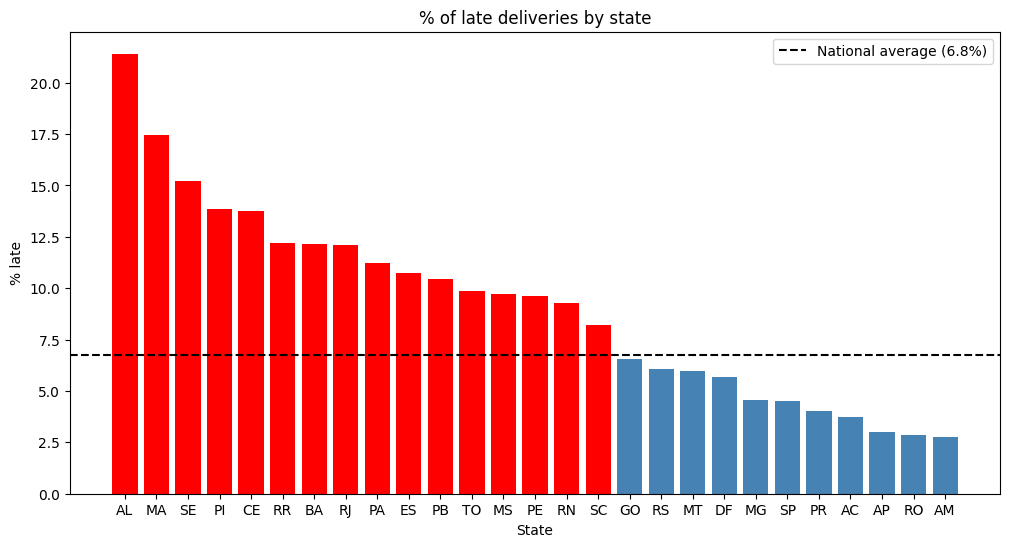

In [22]:
national_late_pct = delivered["is_late"].mean() * 100
colors = ["red" if x > national_late_pct else "steelblue" for x in state_summary["late_pct"]]

plt.figure(figsize=(12, 6))
plt.bar(state_summary.index, state_summary["late_pct"], color=colors)
plt.axhline(national_late_pct, color="black", linestyle="--", label=f"National average ({national_late_pct:.1f}%)")
plt.title("% of late deliveries by state")
plt.xlabel("State")
plt.ylabel("% late")
plt.legend()
plt.show()

### 5.3 Are remote states worse?

Most sellers and the main hubs are in the Southeast (around São Paulo).
We group states into Brazil's 5 regions to see if regions far from there have more late orders.

             orders  late_pct  avg_review
region                                   
Northeast      9044     12.72        3.97
North          1796      8.57        4.03
Center-West    5624      6.53        4.13
Southeast     66193      6.12        4.18
South         13813      5.90        4.19


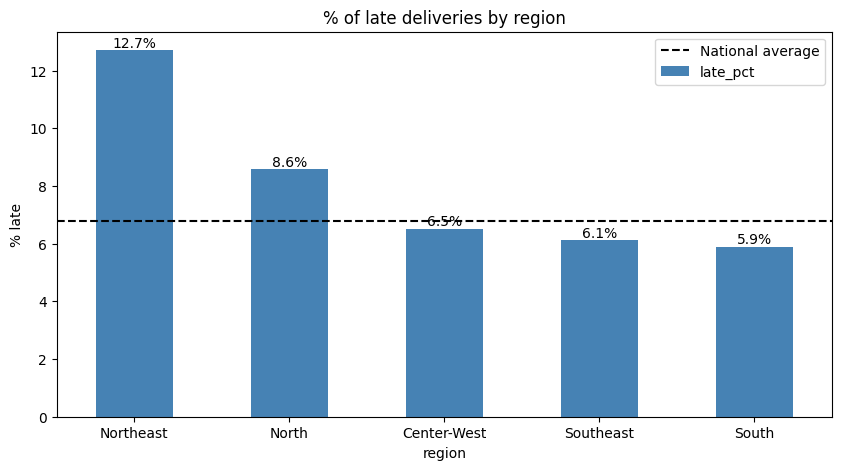

In [23]:
regions = {
    "AC": "North", "AP": "North", "AM": "North", "PA": "North",
    "RO": "North", "RR": "North", "TO": "North",
    "AL": "Northeast", "BA": "Northeast", "CE": "Northeast", "MA": "Northeast",
    "PB": "Northeast", "PE": "Northeast", "PI": "Northeast", "RN": "Northeast", "SE": "Northeast",
    "DF": "Center-West", "GO": "Center-West", "MT": "Center-West", "MS": "Center-West",
    "ES": "Southeast", "MG": "Southeast", "RJ": "Southeast", "SP": "Southeast",
    "PR": "South", "RS": "South", "SC": "South",
}
delivered["region"] = delivered["customer_state"].map(regions)
state_summary["region"] = state_summary.index.map(regions)

region_summary = delivered.groupby("region").agg(
    orders=("order_id", "count"),
    late_pct=("is_late", "mean"),
    avg_review=("review_score", "mean"),
)
region_summary["late_pct"] = region_summary["late_pct"] * 100
region_summary = region_summary.sort_values("late_pct", ascending=False)
print(region_summary.round(2))

ax = region_summary["late_pct"].plot(kind="bar", color="steelblue")
ax.bar_label(ax.containers[0], fmt="%.1f%%")
plt.axhline(national_late_pct, color="black", linestyle="--", label="National average")
plt.title("% of late deliveries by region")
plt.ylabel("% late")
plt.xticks(rotation=0)
plt.legend()
plt.show()

Some states have very few orders, so their percent can jump around a lot.
We list the top 5 worst states and how many orders each one has.

In [24]:
print("Top 5 worst states:")
print(state_summary[["region", "orders", "late_pct"]].head(5).round(1))
print()
print("Top 5 best states:")
print(state_summary[["region", "orders", "late_pct"]].tail(5).round(1))

Top 5 worst states:
                   region  orders  late_pct
customer_state                             
AL              Northeast     397      21.4
MA              Northeast     717      17.4
SE              Northeast     335      15.2
PI              Northeast     476      13.9
CE              Northeast    1279      13.8

Top 5 best states:
               region  orders  late_pct
customer_state                         
PR              South    4923       4.0
AC              North      80       3.8
AP              North      67       3.0
RO              North     243       2.9
AM              North     145       2.8


## Step 6: Story 4 - Do late deliveries cause bad reviews?

We compare review scores for orders that came on time and orders that came late.
If late orders get much lower scores, then logistics is a big part of the problem.

### 6.1 Average review score by delivery status

Delivery_Status
On Time       4.29
Late          2.99
Super Late    1.74
Name: review_score, dtype: float64


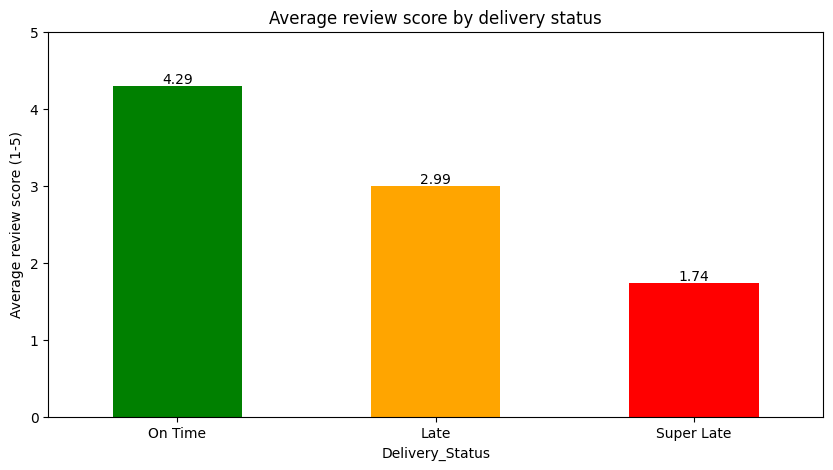

In [25]:
score_by_status = delivered.groupby("Delivery_Status")["review_score"].mean().reindex(status_order)
print(score_by_status.round(2))

ax = score_by_status.plot(kind="bar", color=["green", "orange", "red"])
ax.bar_label(ax.containers[0], fmt="%.2f")
plt.title("Average review score by delivery status")
plt.ylabel("Average review score (1-5)")
plt.ylim(0, 5)
plt.xticks(rotation=0)
plt.show()

### 6.2 Delivery delay vs average review score

Here Delay_Days = how many days late the order was, so negative means early.
We only plot days with at least 30 orders so the line is not noisy.

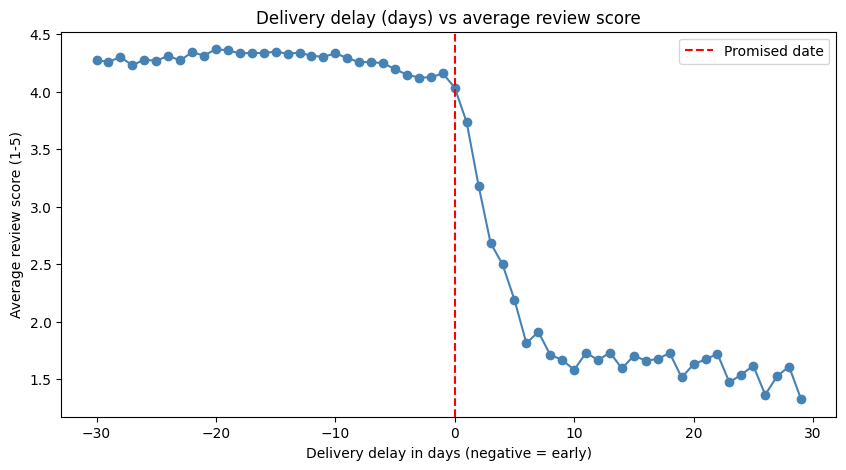

Correlation between delay and review score: -0.27


In [26]:
delivered["Delay_Days"] = -delivered["Days_Difference"]

by_delay = delivered.groupby("Delay_Days").agg(
    avg_review=("review_score", "mean"),
    orders=("order_id", "count"),
)
by_delay = by_delay[(by_delay["orders"] >= 30) & (by_delay.index.to_series().between(-30, 30))]

plt.plot(by_delay.index, by_delay["avg_review"], marker="o", color="steelblue")
plt.axvline(0, color="red", linestyle="--", label="Promised date")
plt.title("Delivery delay (days) vs average review score")
plt.xlabel("Delivery delay in days (negative = early)")
plt.ylabel("Average review score (1-5)")
plt.legend()
plt.show()

corr = delivered["Delay_Days"].corr(delivered["review_score"])
print("Correlation between delay and review score:", round(corr, 2))

### 6.3 Share of bad reviews

A bad review here means a score of 1 or 2.
This shows how much more likely a late customer is to leave one.

Delivery_Status
On Time        9.2
Late          40.4
Super Late    76.1
Name: bad_review, dtype: float64


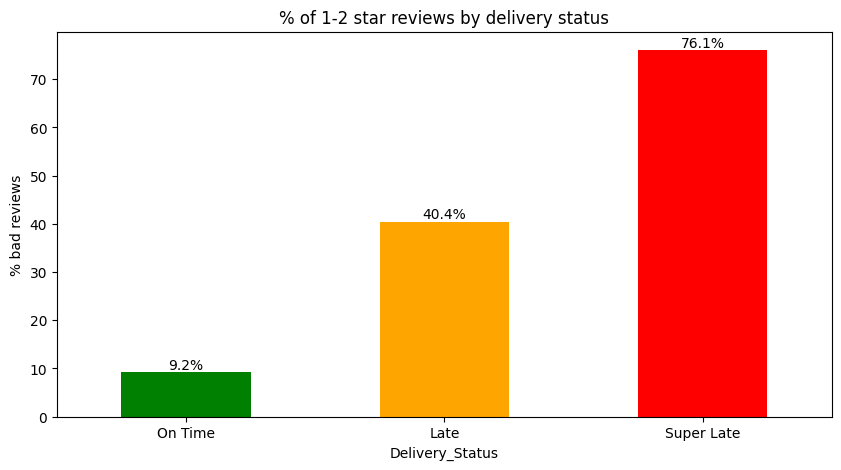

In [27]:
delivered["bad_review"] = delivered["review_score"] <= 2
bad_pct = delivered.groupby("Delivery_Status")["bad_review"].mean().reindex(status_order) * 100
print(bad_pct.round(1))

ax = bad_pct.plot(kind="bar", color=["green", "orange", "red"])
ax.bar_label(ax.containers[0], fmt="%.1f%%")
plt.title("% of 1-2 star reviews by delivery status")
plt.ylabel("% bad reviews")
plt.xticks(rotation=0)
plt.show()

## Step 7: Bonus - Product categories in English

We link each order to its products and turn the Portuguese category names into English.
Then we check which categories are delivered late most often.

### 7.1 Translate the categories

One order can have products from more than one category, so we count each order once per category.
We do this in a separate table so the master table does not get duplicate rows.

In [28]:
order_products = items[["order_id", "product_id"]].drop_duplicates()
order_products = order_products.merge(products[["product_id", "product_category_name"]], on="product_id", how="left")
order_products = order_products.merge(translation, on="product_category_name", how="left")

order_products["category"] = order_products["product_category_name_english"]
order_products["category"] = order_products["category"].fillna(order_products["product_category_name"])
order_products["category"] = order_products["category"].fillna("unknown")

order_categories = order_products[["order_id", "category"]].drop_duplicates()
order_categories = order_categories.merge(
    delivered[["order_id", "is_late", "review_score", "Days_Difference"]],
    on="order_id",
    how="inner",
)

order_categories.head()

,order_id,category,is_late,review_score,Days_Difference
0,00010242fe8c5a6d1ba2dd792cb16214,cool_stuff,False,5.0,9.0
1,00018f77f2f0320c557190d7a144bdd3,pet_shop,False,4.0,3.0
2,000229ec398224ef6ca0657da4fc703e,furniture_decor,False,5.0,14.0
3,00024acbcdf0a6daa1e931b038114c75,perfumery,False,4.0,6.0
4,00042b26cf59d7ce69dfabb4e55b4fd9,garden_tools,False,5.0,16.0


### 7.2 Late percent by category

We only keep categories with at least 300 orders so small groups do not mislead us.
The chart shows the 15 categories with the highest late percent.

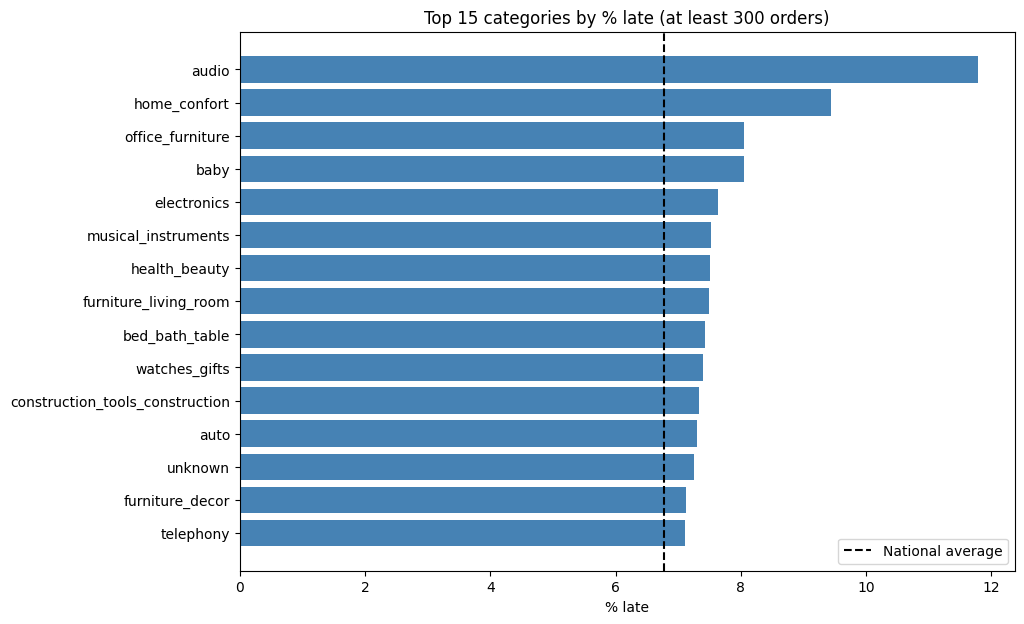

In [29]:
category_summary = order_categories.groupby("category").agg(
    orders=("order_id", "count"),
    late_pct=("is_late", "mean"),
    avg_review=("review_score", "mean"),
)
category_summary["late_pct"] = category_summary["late_pct"] * 100
category_summary = category_summary[category_summary["orders"] >= 300]
category_summary = category_summary.sort_values("late_pct", ascending=False)

top15 = category_summary.head(15).sort_values("late_pct")
plt.figure(figsize=(10, 7))
plt.barh(top15.index, top15["late_pct"], color="steelblue")
plt.axvline(national_late_pct, color="black", linestyle="--", label="National average")
plt.title("Top 15 categories by % late (at least 300 orders)")
plt.xlabel("% late")
plt.legend()
plt.show()

### 7.3 Is furniture harder to ship than electronics?

We pull out the furniture and electronics categories and compare them side by side.

In [30]:
furniture = [c for c in category_summary.index if "furniture" in c]
electronics = [c for c in category_summary.index if c in ["electronics", "computers_accessories", "telephony", "computers"]]

print(category_summary.loc[furniture + electronics].round(2))

                       orders  late_pct  avg_review
category                                           
office_furniture         1254      8.05        3.64
furniture_living_room     414      7.49        4.07
furniture_decor          6307      7.12        4.06
electronics              2517      7.63        4.12
telephony                4093      7.11        4.05
computers_accessories    6529      6.39        4.08


## Step 8: Candidate's Choice - Monthly trend of late orders and reviews

The CEO noticed a recent spike in bad reviews, so we track late orders and review scores month by month.
If both lines move together, it shows when the problem started and that delivery is driving it.

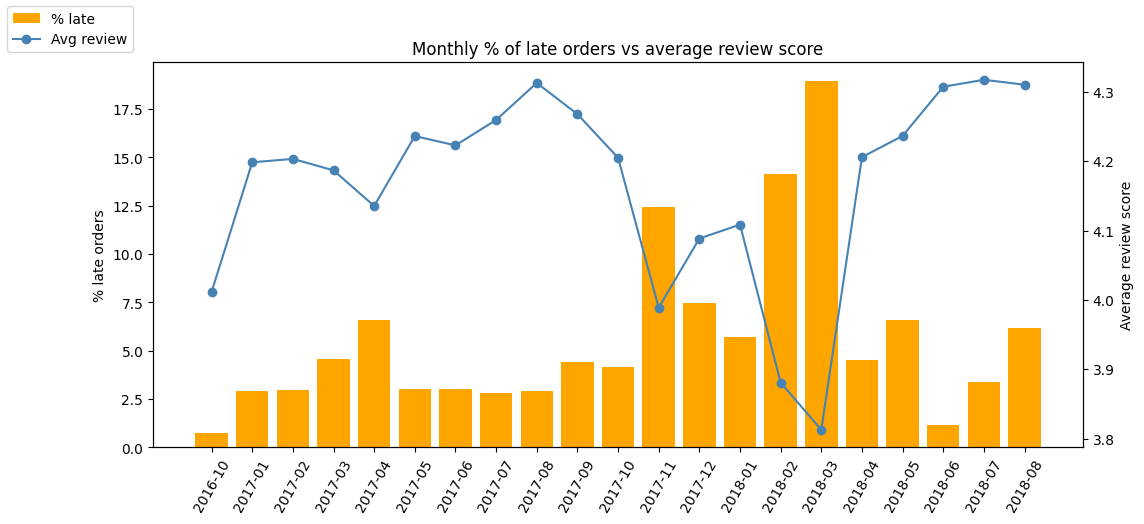

Correlation between monthly late % and monthly avg review: -0.8

Worst 3 months for late orders:
         orders  late_pct  avg_review
month                                
2018-03    7003     18.96        3.81
2018-02    6555     14.13        3.88
2017-11    7288     12.40        3.99


In [31]:
delivered["month"] = delivered["order_purchase_timestamp"].dt.to_period("M").astype(str)

monthly = delivered.groupby("month").agg(
    orders=("order_id", "count"),
    late_pct=("is_late", "mean"),
    avg_review=("review_score", "mean"),
)
monthly["late_pct"] = monthly["late_pct"] * 100
monthly = monthly[monthly["orders"] >= 100]

fig, ax1 = plt.subplots(figsize=(12, 5))
ax1.bar(monthly.index, monthly["late_pct"], color="orange", label="% late")
ax1.set_ylabel("% late orders")
ax1.tick_params(axis="x", rotation=60)

ax2 = ax1.twinx()
ax2.plot(monthly.index, monthly["avg_review"], color="steelblue", marker="o", label="Avg review")
ax2.set_ylabel("Average review score")

plt.title("Monthly % of late orders vs average review score")
fig.legend(loc="upper left")
plt.show()

print("Correlation between monthly late % and monthly avg review:", round(monthly["late_pct"].corr(monthly["avg_review"]), 2))
print()
print("Worst 3 months for late orders:")
print(monthly.sort_values("late_pct", ascending=False).head(3).round(2))

## Step 9: Save files for the dashboard

We save clean tables as CSV files so we can load them into the dashboard tool.
They go in the data/dashboard folder, which is not uploaded to GitHub.

In [32]:
import os
os.makedirs("data/dashboard", exist_ok=True)

dashboard_cols = [
    "order_id", "order_status", "customer_state", "customer_city",
    "order_purchase_timestamp", "order_estimated_delivery_date", "order_delivered_customer_date",
    "Days_Difference", "Delay_Days", "Delivery_Status", "is_late", "review_score", "region", "month",
]
delivered[dashboard_cols].to_csv("data/dashboard/orders.csv", index=False)
state_summary.reset_index().to_csv("data/dashboard/states.csv", index=False)
category_summary.reset_index().to_csv("data/dashboard/categories.csv", index=False)
monthly.reset_index().to_csv("data/dashboard/monthly.csv", index=False)

print("Saved 4 files for the dashboard.")

Saved 4 files for the dashboard.


## Step 10: Key findings

This cell prints the main numbers in one place.
We use them to write the Executive Summary in the README.

In [33]:
print("Total orders:", len(master))
print("Delivered orders used:", len(delivered))
print("Not delivered (left out):", (~master["is_delivered"]).sum())
print()
print(f"National late rate: {national_late_pct:.1f}%")
print(f"Super late rate: {(delivered['Delivery_Status'] == 'Super Late').mean() * 100:.1f}%")
print(f"Average days promised: {promised_days.mean():.1f} | average days taken: {actual_days.mean():.1f}")
print()
print("Worst 3 states:", ", ".join(f"{s} ({p:.1f}%)" for s, p in state_summary["late_pct"].head(3).items()))
print("Worst region:", region_summary.index[0], f"({region_summary['late_pct'].iloc[0]:.1f}%)")
print("Best region:", region_summary.index[-1], f"({region_summary['late_pct'].iloc[-1]:.1f}%)")
print()
print("Average review score:")
for status, score in score_by_status.items():
    print(f"  {status:11} {score:.2f}")

Total orders: 99441
Delivered orders used: 96470
Not delivered (left out): 2971

National late rate: 6.8%
Super late rate: 3.9%
Average days promised: 23.4 | average days taken: 12.1

Worst 3 states: AL (21.4%), MA (17.4%), SE (15.2%)
Worst region: Northeast (12.7%)
Best region: South (5.9%)

Average review score:
  On Time     4.29
  Late        2.99
  Super Late  1.74


**Conclusion:**

- Only 6.8% of delivered orders are late, but late orders get much worse reviews: 4.29 for on time, 2.99 for late, and 1.74 for super late. About 76% of super late orders get a 1 or 2 star review, so late delivery clearly hurts customer happiness.
- The problem is not nationwide. It is centered in the Northeast (12.7% late, about double the South), with Alagoas (21.4%), Maranhão (17.4%) and Sergipe (15.2%) the worst states.
- The far North is not worse, even though it is remote. Its orders are few, and the estimates there are probably long enough to cover the slow trip.
- On average we promise 23 days but deliver in 12, so most estimates are too long, not too short. The real issue is a few regions and periods: in March 2018, 19% of orders were late, and review scores dropped in the same months.